# TF-IDF Analysis for Transcript Words

Analyzes vocabulary patterns across transcripts using TF-IDF (Term Frequency-Inverse Document Frequency). This helps identify:
- Words that are distinctive to specific recordings
- Common vs. rare words in the dataset
- Word importance for classification tasks (Dementia, MCI, HC)

In [37]:
import re
import numpy as np
import matplotlib.pyplot as plt
import nltk
from nltk.stem import WordNetLemmatizer

from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    accuracy_score, 
    precision_recall_fscore_support
)
from sklearn.utils.sparsefuncs import mean_variance_axis
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

nltk.download('wordnet', quiet=True)

import optuna
import dataloader

## Data Loading and Preprocessing

In [38]:
loader = dataloader.TranscriptLoader()
transcript_paths = loader.discover_transcript_files()

frames_dict = loader.load_all_transcripts(transcript_paths)
metadata = loader.load_metadata()

lemmatizer = WordNetLemmatizer()

def lemma_tokenizer(text):
    tokens = re.split(r'\W+', text.lower())
    return [lemmatizer.lemmatize(w) for w in tokens if len(w) > 1]

diagnosis_by_recording = {
    row['recording']: row['diagnosis']
    for _, row in metadata[['recording', 'diagnosis']].dropna().iterrows()
}

TARGET_TASKS = ('SFT', 'PFT')
# TARGET_DIAGNOSES = ('DEMENTIA', 'MCI', 'HC')
# TARGET_DIAGNOSES = ('DEMENTIA', 'HC')
TARGET_DIAGNOSES = ('DEMENTIA', 'MCI')
# TARGET_DIAGNOSES = ('MCI', 'HC')

task_diagnosis_frames = {
    task: {diagnosis: {} for diagnosis in TARGET_DIAGNOSES}
    for task in TARGET_TASKS
}

for stem, df in frames_dict.items():
    if len(df) == 0: continue

    if 'task' in df.columns:
        task = str(df['task'].iloc[0]).upper()
    else:
        task = 'SFT' if 'SFT' in stem.upper() else 'PFT' if 'PFT' in stem.upper() else 'UNKNOWN'

    recording = str(df['recording'].iloc[0]) if 'recording' in df.columns else None
    diagnosis = diagnosis_by_recording.get(recording, 'UNKNOWN')

    if task in TARGET_TASKS and diagnosis in TARGET_DIAGNOSES:
        task_diagnosis_frames[task][diagnosis][stem] = df

def build_corpus(dataframes, min_tokens=2):
    corpus = []
    for df in dataframes:
        tokens = [t.strip() for t in df['token'].astype(str).tolist() if t.strip()]
        if len(tokens) < min_tokens: continue
        text = ' '.join(df['token'].astype(str).tolist())
        corpus.append(text)
        print(text)
        print("corpus length: ", len(corpus))
    return corpus

## Utility Functions for TF-IDF and Visualization

In [39]:

def plot_tfidf_comparison(task_name, task_data, n_limit=20):
    fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharey=False)
    fig.suptitle(f"Top {n_limit} Stemmed Terms: {task_name} Task", fontsize=18, fontweight='bold')
    
    colors = {
        'Dementia': '#e31a1c', # Bright Red
        'MCI': "#000dff", # Bright Blue
        'HC': '#33a02c' # Bright Green
    }

    for idx, diagnosis in enumerate(['HC', 'MCI', 'DEMENTIA']):
        ax = axes[idx]
        diagnosis_frames = task_data.get(diagnosis, {})
        corpus = build_corpus(diagnosis_frames.values())

        if not corpus:
            ax.text(0.5, 0.5, "No Data Available", ha='center', va='center')
            ax.set_title(f"{diagnosis}")
            continue

        vectorizer = TfidfVectorizer(tokenizer=lemma_tokenizer, token_pattern=None)
        X = vectorizer.fit_transform(corpus)
        feature_names = vectorizer.get_feature_names_out()
        mean_scores = mean_variance_axis(X, axis=0)[0]
        
        sorted_indices = mean_scores.argsort()[::-1][:n_limit]
        top_terms = [feature_names[i] for i in sorted_indices]
        top_values = [mean_scores[i] for i in sorted_indices]

        ax.barh(top_terms, top_values, color=colors.get(diagnosis, 'skyblue'))
        ax.set_title(f"{diagnosis} (n={len(corpus)})", fontsize=14)
        ax.invert_yaxis()
        ax.set_xlabel("Mean TF-IDF Score")
        ax.grid(axis='x', linestyle='--', alpha=0.7)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

## Machine Learning Pipeline

In [40]:

def objective(trial, X, y):
    param_grid = {
        'tfidf__max_features': trial.suggest_int('tfidf__max_features', 20, 100),
        'tfidf__binary': trial.suggest_categorical('tfidf__binary', [True, False]),
        'clf__C': trial.suggest_float('clf__C', 0.1, 10.0, log=True),
        'clf__class_weight': trial.suggest_categorical('clf__class_weight', ['balanced', None])
    }
    
    pipeline = build_pipeline()
    
    pipeline.set_params(**param_grid)
    
    score = cross_val_score(pipeline, X, y, cv=5, scoring='f1_macro').mean()
    return score

def build_pipeline():
    return Pipeline([
    ('tfidf', TfidfVectorizer(
        tokenizer=lemma_tokenizer,
        token_pattern=None,
        max_features=40,
        binary=True,
        sublinear_tf=True
    )),
    ('clf', LogisticRegression(
        class_weight='balanced', 
        solver='lbfgs', 
        max_iter=1000
    ))
    # ('clf', LinearSVC(
    #     class_weight='balanced'
    # ))
])

def run_pipeline_tuning(X, y, n_trials=30):
    study = optuna.create_study(direction='maximize')
    
    # Use a lambda to pass X and y into the objective
    study.optimize(lambda trial: objective(trial, X, y), n_trials=n_trials)
    
    print("\n--- Optuna Optimization Results ---")
    print(f"Best F1-Score: {study.best_value:.4f}")
    print(f"Best Parameters: {study.best_params}")
    
    return study.best_params


def build_dataset(task_diagnosis_frames, tasks, diagnoses, min_tokens=2):
    X, y = [], []
    skipped = 0 
    for task in tasks:
        for diagnosis in diagnoses:
            frames = task_diagnosis_frames[task][diagnosis]
            for stem, df in frames.items():
                tokens = [t.strip() for t in df['token'].astype(str).tolist() if t.strip()]
                if len(tokens) < min_tokens:
                    skipped += 1
                    continue
                X.append(' '.join(tokens))
                y.append(diagnosis)
    print(f"Skipped {skipped} short transcripts")
    return X, y

def run_cv_experiment(X, y, k=5, pipeline=build_pipeline()):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    metrics = []
    conf_matrices = []

    all_y_true = []
    all_y_pred = []
    for train_idx, test_idx in skf.split(X, y):
        X_train, X_test = [X[i] for i in train_idx], [X[i] for i in test_idx]
        y_train, y_test = [y[i] for i in train_idx], [y[i] for i in test_idx]

        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)

        acc = accuracy_score(y_test, y_pred)
        prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted')
        cm = confusion_matrix(y_test, y_pred, labels=TARGET_DIAGNOSES)

        metrics.append((acc, prec, rec, f1))
        conf_matrices.append(cm)

    return np.array(metrics), conf_matrices, all_y_pred, all_y_true

def plot_avg_confusion_matrix(conf_matrices, labels, task_name):
    avg_cm = np.mean(conf_matrices, axis=0)
    plt.figure()
    plt.imshow(avg_cm, cmap='Blues')
    plt.title(f"Average Confusion Matrix ({task_name})")
    plt.colorbar()
    plt.xticks(range(len(labels)), labels)
    plt.yticks(range(len(labels)), labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            plt.text(j, i, f"{avg_cm[i, j]:.2f}", ha="center", va="center")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

## Detailed Analysis

In [41]:
from sklearn.metrics import classification_report

def summarise_detailed_results(metrics, all_y_true, all_y_pred):
    mean = metrics.mean(axis=0)
    std = metrics.std(axis=0)

    print("\n" + "="*30)
    print("DETAILED PERFORMANCE METRICS")
    print("="*30)
    print(f"Overall Accuracy: {mean[0]:.3f} ± {std[0]:.3f}")
    print(f"Weighted F1:      {mean[3]:.3f} ± {std[3]:.3f}")
    print("-" * 30)
    
    # This shows Recall and Precision per class
    print("Per-Class Breakdown (Aggregated):")
    print(classification_report(all_y_true, all_y_pred, target_names=TARGET_DIAGNOSES))

## Final Analysis

[I 2026-05-09 00:46:26,937] A new study created in memory with name: no-name-30a70022-808e-4c5b-b606-98be693e451a


[I 2026-05-09 00:46:27,094] Trial 0 finished with value: 0.4155882352941177 and parameters: {'tfidf__max_features': 75, 'tfidf__binary': True, 'clf__C': 0.5114898381137786, 'clf__class_weight': None}. Best is trial 0 with value: 0.4155882352941177.



===== TASK: SFT =====
Skipped 0 short transcripts


[I 2026-05-09 00:46:27,279] Trial 1 finished with value: 0.5914790764790766 and parameters: {'tfidf__max_features': 93, 'tfidf__binary': True, 'clf__C': 3.9455805320183535, 'clf__class_weight': 'balanced'}. Best is trial 1 with value: 0.5914790764790766.
[I 2026-05-09 00:46:27,453] Trial 2 finished with value: 0.5650091575091576 and parameters: {'tfidf__max_features': 83, 'tfidf__binary': False, 'clf__C': 2.7910950320092573, 'clf__class_weight': None}. Best is trial 1 with value: 0.5914790764790766.
[I 2026-05-09 00:46:27,609] Trial 3 finished with value: 0.5927860374919198 and parameters: {'tfidf__max_features': 100, 'tfidf__binary': True, 'clf__C': 1.5789814459138682, 'clf__class_weight': None}. Best is trial 3 with value: 0.5927860374919198.
[I 2026-05-09 00:46:27,769] Trial 4 finished with value: 0.64 and parameters: {'tfidf__max_features': 25, 'tfidf__binary': True, 'clf__C': 1.531765431891093, 'clf__class_weight': 'balanced'}. Best is trial 4 with value: 0.64.
[I 2026-05-09 00:46


--- Optuna Optimization Results ---
Best F1-Score: 0.6522
Best Parameters: {'tfidf__max_features': 55, 'tfidf__binary': False, 'clf__C': 0.12416963100639238, 'clf__class_weight': 'balanced'}

DETAILED PERFORMANCE METRICS
Overall Accuracy: 0.684 ± 0.196
Weighted F1:      0.682 ± 0.193
------------------------------
Per-Class Breakdown (Aggregated):
              precision    recall  f1-score   support

    DEMENTIA       0.61      0.67      0.64        21
         MCI       0.75      0.70      0.72        30

    accuracy                           0.69        51
   macro avg       0.68      0.68      0.68        51
weighted avg       0.69      0.69      0.69        51

Accuracy: 0.684 ± 0.196
F1-score: 0.682 ± 0.193


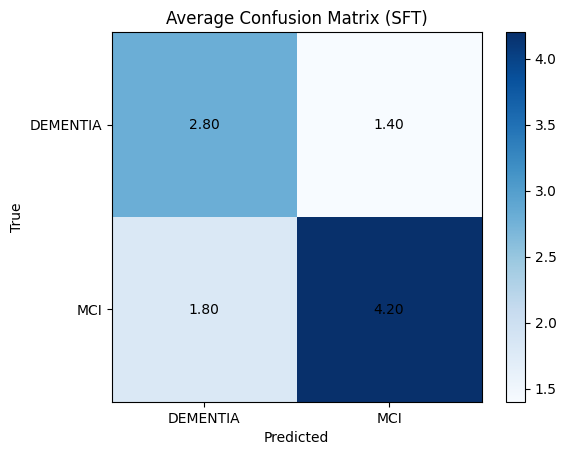

cheetah lion panda panda elephant giraffe springbok zebra rhinoceros armadillo fox eagle peacock hummingbird robin hippopotamus
corpus length:  1
Ant Aardvark Antelope Bear Bull Beetle ? Chihuahua Cow Cormorant  Dog Deer Elephant Egret Flamingo ? Goats Gazelle Giraffe Hippo Monkey ? Whale Zebra Rhino Snake Serpent
corpus length:  2
Aardvark Bat Cat Donkey Elephant Fox Goat Hound Iguana Jack Rabbit Kangaroo Lion Mouse Orangutan Possum Rabbit Snake Tiger Umbrellabird
corpus length:  3
Pigeons Sparrow Elephant Rhino Lion Tiger Wolf Robin Blackbird Rhino Snails Worms Ants Spiders Ants Red Ants Black Ants
corpus length:  4
Cat Lion Tiger Elephant Antelope Cow Bull Duck Hen Cock Turkey Hamster
corpus length:  5
Dog Mouse Lion Tigers Giraffe Rhino Snake Hamsters Mice Rats Elephant Zebras Cows Sheep
corpus length:  6
Kangaroo Cow Sheep Rat Zebra Elephant Rhinoceros Sheep Bull Cow Cat Birds Lion Tiger Squirrel Hedgehog Poochie Parrot Camel
corpus length:  7
Dog Cat Bird Mouse Hamster Budgerigar

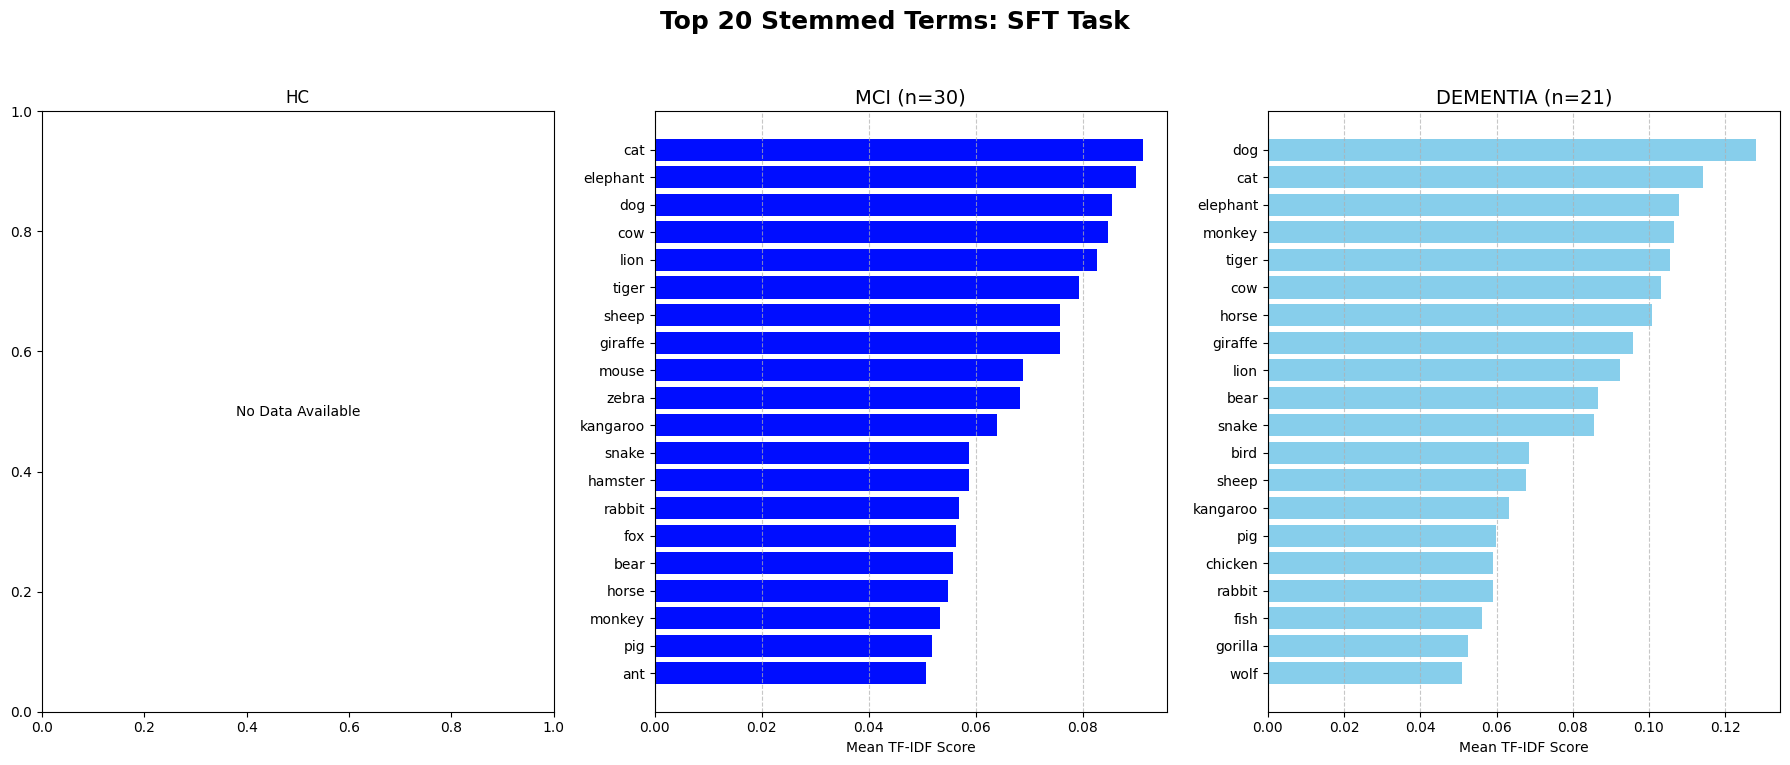

[I 2026-05-09 00:46:30,570] A new study created in memory with name: no-name-4f2fa585-15d8-4e4f-8d09-daa022fad8ae
[I 2026-05-09 00:46:30,665] Trial 0 finished with value: 0.4673076923076923 and parameters: {'tfidf__max_features': 68, 'tfidf__binary': True, 'clf__C': 2.6223274654610615, 'clf__class_weight': None}. Best is trial 0 with value: 0.4673076923076923.



===== TASK: PFT =====
Skipped 1 short transcripts


[I 2026-05-09 00:46:30,789] Trial 1 finished with value: 0.355 and parameters: {'tfidf__max_features': 82, 'tfidf__binary': True, 'clf__C': 0.936138647330543, 'clf__class_weight': None}. Best is trial 0 with value: 0.4673076923076923.
[I 2026-05-09 00:46:30,933] Trial 2 finished with value: 0.39282051282051283 and parameters: {'tfidf__max_features': 73, 'tfidf__binary': False, 'clf__C': 5.938014927367396, 'clf__class_weight': None}. Best is trial 0 with value: 0.4673076923076923.
[I 2026-05-09 00:46:31,040] Trial 3 finished with value: 0.3759157509157509 and parameters: {'tfidf__max_features': 82, 'tfidf__binary': False, 'clf__C': 7.16594980010184, 'clf__class_weight': None}. Best is trial 0 with value: 0.4673076923076923.
[I 2026-05-09 00:46:31,136] Trial 4 finished with value: 0.38 and parameters: {'tfidf__max_features': 55, 'tfidf__binary': True, 'clf__C': 0.38904120666546443, 'clf__class_weight': None}. Best is trial 0 with value: 0.4673076923076923.
[I 2026-05-09 00:46:31,220] Tri


--- Optuna Optimization Results ---
Best F1-Score: 0.5067
Best Parameters: {'tfidf__max_features': 20, 'tfidf__binary': True, 'clf__C': 1.5719140395788072, 'clf__class_weight': None}

DETAILED PERFORMANCE METRICS
Overall Accuracy: 0.467 ± 0.143
Weighted F1:      0.470 ± 0.139
------------------------------
Per-Class Breakdown (Aggregated):
              precision    recall  f1-score   support

    DEMENTIA       0.35      0.42      0.38        19
         MCI       0.58      0.50      0.54        30

    accuracy                           0.47        49
   macro avg       0.46      0.46      0.46        49
weighted avg       0.49      0.47      0.48        49

Accuracy: 0.467 ± 0.143
F1-score: 0.470 ± 0.139


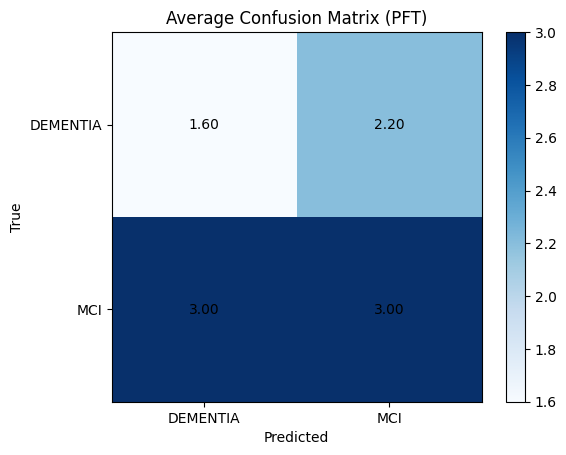

plank pool pool plepthora puzzle place point paper paint pencil power please people plastic plate prevent provide perhaps papyrus perplexed promote promotion pandemic panic
corpus length:  1
Pope Pal Pitch Plots Pawn Property Post Pram Prove Prank Pill Push Paper Paparazzi Peer Plush Pen Pencil Pork People Prove ? Pert Pump Pendulum
corpus length:  2
Pack Push Pole Present Punch Pinch Penelope Porcupine Pierce Poke Piddle Puddle Power Piddle Psychology Port Passion Penelope Peter Porcelain
corpus length:  3
Puzzles Punchbowl Potatoes Pyramid Pound Pontiac Planning Pram Prestigous People Pianist Private Pony Prance People Popal Pope Pendragon
corpus length:  4
Paper Petrol Policeman Patrol Positive Parafernalia Paper Paragraph Puppy Pencil Pen Parafernalia Present Past Plan Pleasant Place
corpus length:  5
Petrol Puma
corpus length:  6
Palace Picture Portrait Photo Plass Person Pickle Pasture Pillow Pand? Possible
corpus length:  7
Prince Photograph Pin Punch Play Photograph
corpus leng

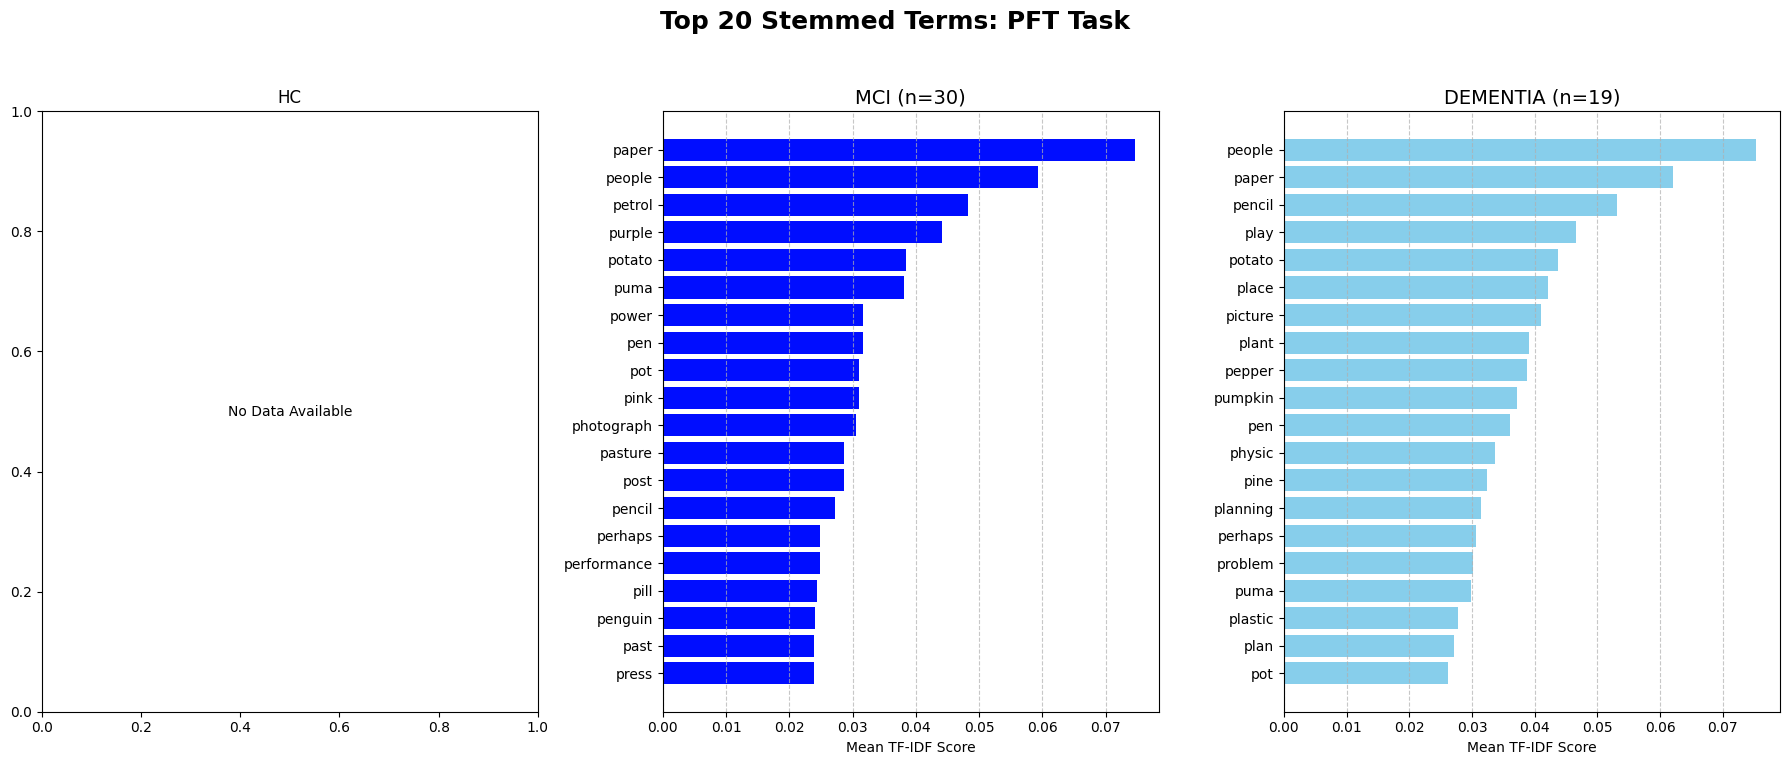

In [42]:
for task in TARGET_TASKS:
    print(f"\n===== TASK: {task} =====")
    X, y = build_dataset(task_diagnosis_frames, [task], TARGET_DIAGNOSES)
    
    if not X:
        print(f"No valid data for {task}")
        continue

    
    best_hyperparams = run_pipeline_tuning(X, y, n_trials=20)
    
    optimized_pipeline = build_pipeline()
    optimized_pipeline.set_params(**best_hyperparams)
    
    metrics, cms, all_y_pred, all_y_true = run_cv_experiment(X, y)
    summarise_detailed_results(metrics, all_y_true, all_y_pred)
    
    mean, std = metrics.mean(axis=0), metrics.std(axis=0)
    print(f"Accuracy: {mean[0]:.3f} ± {std[0]:.3f}")
    print(f"F1-score: {mean[3]:.3f} ± {std[3]:.3f}")

    plot_avg_confusion_matrix(cms, TARGET_DIAGNOSES, task)
    plot_tfidf_comparison(task, task_diagnosis_frames[task], 20)